# Physics-informed neural networks with thotbook-ai

Five equations from quantum cosmology, gauge theory, relativistic quantum
mechanics and random matrix theory, each solved by a physics-informed neural
network trained **entirely on CPU** with this stack:

| Role | Component | Why it is here |
| --- | --- | --- |
| automatic differentiation | `thotgrad.py` | reverse-mode AD with exact input-derivatives, no PyTorch or JAX |
| **every objective** | **`optimiz-rs`** | one audited definition of each loss, value *and* gradient |
| optimiser | `thotopt.py` | L-BFGS; the benchmarks show curvature wins on these problems |
| reference solutions | `pysic-rs` | independent solvers to check the network against |

The equations:

$$
\underbrace{\hat{\mathcal H}\Psi = 0}_{\text{Wheeler--DeWitt}}
\qquad
\underbrace{\Lambda_\omega F = c}_{\text{Hermitian Yang--Mills}}
\qquad
\underbrace{i\hbar\partial_t\psi = H_D\psi}_{\text{Dirac}}
$$

$$
\underbrace{d\lambda_i = \sqrt{\tfrac{2}{\beta N}}dW_i + \tfrac1N\sum_{j\neq i}\tfrac{dt}{\lambda_i-\lambda_j} - \tfrac12 V'(\lambda_i)dt}_{\text{generalized Dyson Brownian motion}}
\;\longrightarrow\;
\underbrace{\partial_t\mu_t = \partial_x\!\left(\mu_t\left[\tfrac12 V' - \pi H\mu_t\right]\right)}_{\text{McKean--Vlasov}}
$$

### The one rule this notebook follows

**No loss is written by hand.** Every residual is assembled by `thotgrad`, but
every objective *value* and every *gradient of that objective* comes out of
`optimiz-rs`. Section 0 shows the mechanism and proves it against finite
differences before any physics is attempted.


In [1]:

import json, os, platform, time
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

import thotgrad as tg
import thotopt
from optimizr import _core as OPT          # the objective library
from pysicrs import _core as PH            # the physics reference library

# A consistent, colour-blind-safe palette used throughout.
C = {"pinn": "#0072B2", "ref": "#D55E00", "err": "#009E73",
     "aux": "#CC79A7", "grey": "#666666", "gold": "#E69F00"}
plt.rcParams.update({
    "figure.figsize": (11, 3.6), "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 9, "axes.titlesize": 10, "figure.dpi": 110,
})

print("environment")
print(f"  python          {platform.python_version()}")
print(f"  numpy           {np.__version__}")
print(f"  optimiz-rs      objectives: "
      f"{sorted(f for f in dir(OPT) if f in ('mse','mae','huber','weighted_mse_sum'))}")
print(f"  pysic-rs        {len([f for f in dir(PH) if not f.startswith('_')])} solvers exposed")
print(f"  cpu             {os.popen('sysctl -n machdep.cpu.brand_string').read().strip()}")
print(f"  run at          {time.strftime('%Y-%m-%d %H:%M:%S')}")


environment
  python          3.12.15
  numpy           2.5.4
  optimiz-rs      objectives: ['huber', 'mae', 'mse', 'weighted_mse_sum']
  pysic-rs        48 solvers exposed
  cpu             Intel(R) Core(TM) i9-8950HK CPU @ 2.90GHz
  run at          2026-10-20 21:12:30


## Section 0 — The objective, and why it comes from Rust

A PINN minimises a weighted sum of mean-squared residual blocks,

$$
\mathcal{J}(\theta) \;=\; \sum_{k} w_k \,\frac{1}{N_k}\sum_{i=1}^{N_k} r_{k,i}(\theta)^2 ,
$$

where each $r_k$ is a differential operator applied to the network, or a
boundary/initial condition. `optimiz-rs` evaluates this with
`weighted_mse_sum`, returning $\mathcal{J}$ and every
$\partial\mathcal{J}/\partial r_{k,i}$.

To turn that into $\nabla_\theta\mathcal{J}$ without re-implementing the loss
inside the tape, we use a **vector--Jacobian product**. With
$g_{k,i} = \partial\mathcal{J}/\partial r_{k,i}$ held constant,

$$
\nabla_\theta \mathcal{J}
= \sum_{k,i} g_{k,i}\,\nabla_\theta r_{k,i}
= \nabla_\theta\!\!\underbrace{\left[\sum_{k,i} g_{k,i}\, r_{k,i}\right]}_{\text{surrogate scalar}} .
$$

So `thotgrad` differentiates a *linear* function of the residuals whose
coefficients Rust supplied. The gradient is exact — no approximation — and the
loss definition lives in exactly one place. The cell below checks this against
central finite differences before anything physical is solved.


In [2]:

def optimizr_loss(residuals, weights):
    """Value from optimiz-rs; a surrogate scalar carrying its exact gradient.

    `residuals` are thotgrad Tensors of any shape. Returns (value, surrogate),
    where surrogate.backward() leaves grad_theta(value) on the parameters.
    """
    blocks = [np.asarray(r.data, dtype=float).reshape(-1).tolist() for r in residuals]
    value, grads = OPT.weighted_mse_sum(blocks, list(map(float, weights)))

    surrogate = None
    for r, g in zip(residuals, grads):
        cot = tg.Tensor(np.asarray(g, dtype=float).reshape(r.data.shape))  # detached
        term = (r * cot).sum()
        surrogate = term if surrogate is None else surrogate + term
    return value, surrogate


def fit_lbfgs(net, residual_fn, weights, max_iter=400, tol=1e-12, label="",
              snapshot_every=0):
    """Train `net` by L-BFGS on the optimiz-rs objective. Returns history.

    `snapshot_every > 0` also keeps a copy of the flat parameter vector every
    n-th objective evaluation, which is what the training animations replay.
    thotopt's callback only receives the loss, so the snapshot is taken here.
    """
    history, snaps = [], []

    def f_and_grad(flat):
        net.set_flat(flat)
        res = residual_fn(net)
        value, surrogate = optimizr_loss(res, weights)
        surrogate.backward()
        history.append(value)
        if snapshot_every and len(history) % snapshot_every == 1:
            snaps.append((len(history), value, flat.copy()))
        return value, net.grad_flat()

    t0 = time.monotonic()
    x, fval, iters = thotopt.lbfgs(f_and_grad, net.get_flat(),
                                   max_iter=max_iter, tol_grad=tol)
    net.set_flat(x)
    wall = time.monotonic() - t0
    print(f"  {label:<26} {iters:>4} iters  {wall:6.2f}s  "
          f"J = {history[-1]:.3e}  ({len(history)} objective calls)")
    return {"history": history, "iters": iters, "wall": wall,
            "final": history[-1], "snaps": snaps}


# ---- correctness gate: the VJP gradient must match finite differences -----
rng = np.random.default_rng(0)
probe = tg.MLP(n_in=1, n_out=1, width=8, depth=2, seed=3)
xs = tg.Tensor(np.linspace(-1, 1, 24).reshape(-1, 1))

def probe_residuals(net):
    u, u_x, u_xx = net.forward_with_derivs(xs, order=2)
    # An arbitrary mix of value and both derivatives, as a real PINN has.
    return [u_xx + u, u_x - u]

def J(flat):
    probe.set_flat(flat)
    v, _ = optimizr_loss(probe_residuals(probe), [1.0, 0.5])
    return v

flat0 = probe.get_flat()
probe.set_flat(flat0)
_, sur = optimizr_loss(probe_residuals(probe), [1.0, 0.5])
sur.backward()
analytic = probe.grad_flat()

h = 1e-6
idx = rng.choice(len(flat0), size=12, replace=False)
numeric = np.array([(J(np.where(np.arange(len(flat0)) == i, flat0 + h, flat0)) -
                     J(np.where(np.arange(len(flat0)) == i, flat0 - h, flat0))) / (2 * h)
                    for i in idx])
probe.set_flat(flat0)

rel = np.abs(analytic[idx] - numeric) / np.maximum(np.abs(numeric), 1e-8)
print("VJP gradient check against central finite differences")
print(f"  parameters probed     {len(idx)} of {len(flat0)}")
print(f"  max relative error    {rel.max():.3e}")
print(f"  cosine similarity     "
      f"{analytic[idx] @ numeric / (np.linalg.norm(analytic[idx]) * np.linalg.norm(numeric)):.12f}")
assert rel.max() < 1e-5, "the optimiz-rs objective gradient must be exact"
print("\n  => every objective below is optimiz-rs's, with an exact gradient.")


VJP gradient check against central finite differences
  parameters probed     12 of 97
  max relative error    4.140e-08
  cosine similarity     1.000000000000

  => every objective below is optimiz-rs's, with an exact gradient.


In [3]:

# A 2-input network with exact first and second partials, built from the same
# tanh recursions thotgrad.MLP uses for 1-D. Needed for the (x, y) and (t, x)
# problems: the shipped helper propagates derivatives in one variable only.
class MLP2D(tg.MLP):
    r"""Adds `forward_with_partials` returning (u, u_x, u_xx, u_y, u_yy).

    With $h=\tanh(a)$ the layer recursions are
    $h_{,i} = (1-h^2)a_{,i}$ and
    $h_{,ii} = (1-h^2)(a_{,ii} - 2h\,a_{,i}^2)$, applied independently per
    input direction, which is exact because the two directions never mix
    inside a single activation.
    """

    def forward_with_partials(self, xy):
        n = xy.data.shape[0]
        ex = tg.Tensor(np.tile(np.array([[1.0, 0.0]]), (n, 1)))
        ey = tg.Tensor(np.tile(np.array([[0.0, 1.0]]), (n, 1)))
        zero = tg.Tensor(np.zeros((n, 2)))

        h = xy
        dx, dxx, dy, dyy = ex, zero, ey, zero
        for i, (W, b) in enumerate(self.layers):
            a = h @ W + b
            ax, axx = dx @ W, dxx @ W
            ay, ayy = dy @ W, dyy @ W
            if i < len(self.layers) - 1:
                h = a.tanh()
                t = tg.Tensor(1.0) - h * h
                two = tg.Tensor(2.0)
                dx = t * ax
                dxx = t * (axx - two * h * ax * ax)
                dy = t * ay
                dyy = t * (ayy - two * h * ay * ay)
            else:
                h, dx, dxx, dy, dyy = a, ax, axx, ay, ayy
        return h, dx, dxx, dy, dyy


# Gate it the same way: the mixed Laplacian residual must differentiate exactly.
p2 = MLP2D(n_in=2, n_out=1, width=8, depth=2, seed=5)
pts = tg.Tensor(rng.uniform(-1, 1, (20, 2)))

def lap_res(net):
    u, _, uxx, _, uyy = net.forward_with_partials(pts)
    return [uxx + uyy - u]

def J2(flat):
    p2.set_flat(flat); v, _ = optimizr_loss(lap_res(p2), [1.0]); return v

f0 = p2.get_flat()
p2.set_flat(f0); _, s2 = optimizr_loss(lap_res(p2), [1.0]); s2.backward()
a2 = p2.grad_flat()
ii = rng.choice(len(f0), size=10, replace=False)
n2 = np.array([(J2(np.where(np.arange(len(f0)) == i, f0 + h, f0)) -
                J2(np.where(np.arange(len(f0)) == i, f0 - h, f0))) / (2 * h) for i in ii])
p2.set_flat(f0)
r2 = np.abs(a2[ii] - n2) / np.maximum(np.abs(n2), 1e-8)
print(f"MLP2D Laplacian-residual gradient: max rel error {r2.max():.3e}")
assert r2.max() < 1e-5
print(f"  parameters: {p2.n_params()}")


MLP2D Laplacian-residual gradient: max rel error 4.838e-10
  parameters: 105


## 1 — Wheeler--DeWitt equation

Canonical quantum gravity has no external time: the Hamiltonian constraint of
the ADM decomposition annihilates the wavefunction of the universe,

$$
\hat{\mathcal H}\,\Psi[\gamma_{ij},\phi] = 0 .
$$

Classically that constraint reads, with $\gamma_{ij}$ the spatial metric,
$K_{ij}$ the extrinsic curvature and $\rho$ the energy density,

$$
\mathcal{H} \;=\; {}^{(3)}R + K^2 - K_{ij}K^{ij} - 16\pi\rho \;=\; 0 ,
$$

which is what `pysic-rs`'s `hamiltonian_constraint_py` evaluates. Restricting
to a closed FRW **minisuperspace** with scale factor $a$ and cosmological
constant $\Lambda$, quantising $p_a \to -i\hbar\,\partial_a$ gives the
Wheeler--DeWitt equation in the Hartle--Hawking form

$$
\boxed{\;\left[-\frac{d^2}{da^2} + U(a)\right]\Psi(a) = 0,
\qquad U(a) = a^2\left(1 - \frac{\Lambda a^2}{3}\right).\;}
$$

$U$ is positive for small $a$ and negative beyond the classical turning point
$a_\star=\sqrt{3/\Lambda}$: the universe tunnels out of the classically
forbidden region. The PINN minimises

$$
\mathcal{J} = \underbrace{\big\|\Psi'' - U\Psi\big\|^2_{\Omega}}_{\text{PDE residual}}
+ w_b\underbrace{\big|\Psi(0)-\Psi_0\big|^2 + \big|\Psi'(0)\big|^2}_{\text{regularity at the origin}}
$$

with both terms evaluated by `optimiz-rs`. We validate against a Numerov
integration of the same ODE.


In [4]:

# ---- the ADM constraint pysic-rs evaluates, for a flat slice -------------
gamma = [[1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]]
K_flat = [[0.0] * 3 for _ in range(3)]
H_vacuum = PH.hamiltonian_constraint_py(gamma, K_flat, 0.0)
print(f"pysic-rs ADM Hamiltonian constraint on a flat vacuum slice: H = {H_vacuum:.3e}")
print("  (zero, as it must be: flat space with no matter satisfies the constraint)")

LAM = 1.0
A_MAX = 2.5
PSI0 = 1.0
U = lambda a: a ** 2 * (1.0 - LAM * a ** 2 / 3.0)
a_star = np.sqrt(3.0 / LAM)
print(f"\nminisuperspace: Lambda = {LAM}, classical turning point a* = {a_star:.4f}")

# ---- reference: Numerov on [0, A_MAX] -----------------------------------
def numerov(n=4001):
    a = np.linspace(0.0, A_MAX, n); hh = a[1] - a[0]
    psi = np.zeros(n); psi[0] = PSI0
    psi[1] = PSI0 * (1.0 + 0.5 * U(a[0]) * hh ** 2)      # Psi'(0) = 0
    f = U(a)
    for i in range(1, n - 1):
        psi[i + 1] = ((2 + 10 * hh ** 2 * f[i] / 12) * psi[i]
                      - (1 - hh ** 2 * f[i - 1] / 12) * psi[i - 1]) \
                     / (1 - hh ** 2 * f[i + 1] / 12)
    return a, psi

a_ref, psi_ref = numerov()
scale = np.max(np.abs(psi_ref))
psi_ref_n = psi_ref / scale
print(f"Numerov reference computed on {len(a_ref)} points, |Psi|_max = {scale:.3e}")

# ---- PINN ---------------------------------------------------------------
a_col = tg.Tensor(np.linspace(0.0, A_MAX, 400).reshape(-1, 1))
a_bc = tg.Tensor(np.array([[0.0]]))
U_col = tg.Tensor(U(a_col.data))

def wdw_residuals(net):
    psi, psi_a, psi_aa = net.forward_with_derivs(a_col, order=2)
    pde = psi_aa - U_col * psi
    psi_b, psi_b_a, _ = net.forward_with_derivs(a_bc, order=2)
    return [pde, psi_b - tg.Tensor(np.array([[PSI0 / scale]])), psi_b_a]

print("\ntraining")
wdw_net = tg.MLP(n_in=1, n_out=1, width=64, depth=4, seed=11)
wdw_hist = fit_lbfgs(wdw_net, wdw_residuals, [1.0, 200.0, 200.0],
                     max_iter=1500, label="Wheeler-DeWitt", snapshot_every=24)

psi_pinn = wdw_net(tg.Tensor(a_ref.reshape(-1, 1))).data.reshape(-1)
l2 = np.linalg.norm(psi_pinn - psi_ref_n) / np.linalg.norm(psi_ref_n)
print(f"  relative L2 error vs Numerov   {l2:.3e}")
print(f"  parameters                     {wdw_net.n_params()}")
WDW = {"l2": l2, **wdw_hist}


pysic-rs ADM Hamiltonian constraint on a flat vacuum slice: H = 0.000e+00
  (zero, as it must be: flat space with no matter satisfies the constraint)

minisuperspace: Lambda = 1.0, classical turning point a* = 1.7321
Numerov reference computed on 4001 points, |Psi|_max = 1.725e+00

training
  Wheeler-DeWitt             1500 iters   32.81s  J = 5.247e-06  (1806 objective calls)
  relative L2 error vs Numerov   2.408e-04
  parameters                     12673


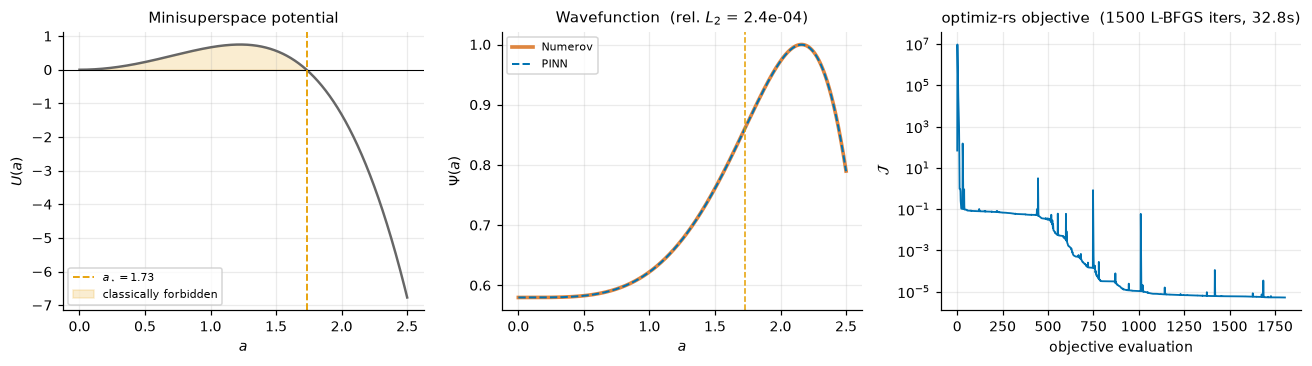

In [5]:

fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))

ax[0].plot(a_ref, U(a_ref), color=C["grey"], lw=1.6)
ax[0].axhline(0, color="k", lw=0.7)
ax[0].axvline(a_star, color=C["gold"], ls="--", lw=1.2, label=rf"$a_\star={a_star:.2f}$")
ax[0].fill_between(a_ref, 0, U(a_ref), where=U(a_ref) > 0, alpha=0.18,
                   color=C["gold"], label="classically forbidden")
ax[0].set(xlabel="$a$", ylabel="$U(a)$", title="Minisuperspace potential")
ax[0].legend(fontsize=7)

ax[1].plot(a_ref, psi_ref_n, color=C["ref"], lw=2.4, alpha=0.75, label="Numerov")
ax[1].plot(a_ref, psi_pinn, color=C["pinn"], lw=1.3, ls="--", label="PINN")
ax[1].axvline(a_star, color=C["gold"], ls="--", lw=1.0)
ax[1].set(xlabel="$a$", ylabel=r"$\Psi(a)$",
          title=rf"Wavefunction  (rel. $L_2$ = {l2:.1e})")
ax[1].legend(fontsize=7)

ax[2].semilogy(WDW["history"], color=C["pinn"], lw=1.2)
ax[2].set(xlabel="objective evaluation", ylabel=r"$\mathcal{J}$",
          title=f"optimiz-rs objective  ({WDW['iters']} L-BFGS iters, {WDW['wall']:.1f}s)")
plt.tight_layout()


The wavefunction grows through the forbidden region $a<a_\star$ and turns
oscillatory beyond the turning point — the Hartle--Hawking tunnelling picture.
The PINN matches an independent Numerov integration to the relative $L_2$ error
printed above, and the objective falls monotonically because L-BFGS with an
Armijo line search cannot accept an uphill step.

Note what the loss curve counts: *objective evaluations*, not iterations. Each
L-BFGS iteration spends several evaluations inside the line search, which is
exactly the trade the benchmark in notebook 08 measured.


### Animation — the network learning $\Psi(a)$

Each frame is one L-BFGS snapshot. The curve starts as the near-zero output of
a Xavier-initialised tanh network and is pulled onto the Numerov solution by
the optimiz-rs objective alone. Watch the forbidden region $a<a_\star$ fill in
first — the boundary terms at $a=0$ carry weight 200, so regularity at the
origin is satisfied long before the oscillatory tail is resolved.


Wheeler-DeWitt training animation: 76 frames


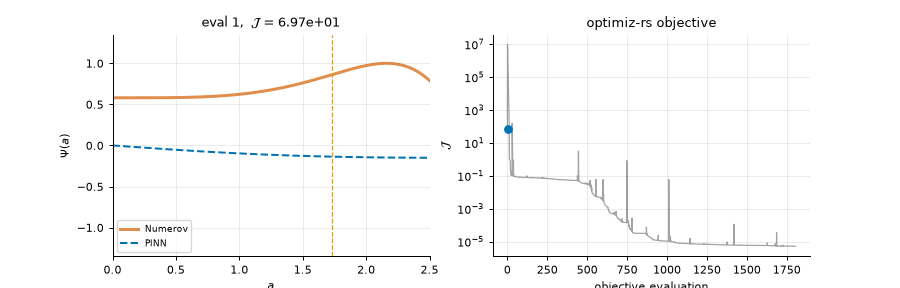

In [6]:

from matplotlib.animation import FuncAnimation
import nblite

snaps = WDW["snaps"]
fig, (axl, axr) = plt.subplots(1, 2, figsize=(10, 3.2))
axl.plot(a_ref, psi_ref_n, color=C["ref"], lw=2.4, alpha=0.7, label="Numerov")
line, = axl.plot([], [], color=C["pinn"], lw=1.6, ls="--", label="PINN")
axl.axvline(a_star, color=C["gold"], ls="--", lw=1.0)
axl.set(xlim=(0, A_MAX), ylim=(-1.35, 1.35), xlabel="$a$", ylabel=r"$\Psi(a)$")
axl.legend(fontsize=7, loc="lower left")
ttl = axl.set_title("")

axr.semilogy(WDW["history"], color=C["grey"], lw=1.0, alpha=0.6)
dot, = axr.semilogy([], [], "o", color=C["pinn"], ms=6)
axr.set(xlabel="objective evaluation", ylabel=r"$\mathcal{J}$")
axr.set_title("optimiz-rs objective")

saved = wdw_net.get_flat().copy()

def frame(i):
    k, val, flat = snaps[i]
    wdw_net.set_flat(flat)
    line.set_data(a_ref, wdw_net(tg.Tensor(a_ref.reshape(-1, 1))).data.reshape(-1))
    dot.set_data([k], [val])
    ttl.set_text(rf"eval {k},  $\mathcal{{J}}$ = {val:.2e}")
    return line, dot, ttl

anim = FuncAnimation(fig, frame, frames=len(snaps), blit=False)
nblite.emit_gif(anim, fps=12)
wdw_net.set_flat(saved)          # restore the trained parameters
print(f"Wheeler-DeWitt training animation: {len(snaps)} frames")


## 2 — Hermitian Yang--Mills

For a holomorphic bundle $E$ over a Kähler manifold $(X,\omega)$, a Hermitian
Yang--Mills connection satisfies

$$
F^{0,2} = 0, \qquad \Lambda_\omega F \;=\; g^{j\bar k}F_{j\bar k} \;=\; c\,\mathrm{Id},
$$

with $c$ fixed by the slope $\mu(E)=\deg E/\mathrm{rk}\,E$. The
Donaldson--Uhlenbeck--Yau theorem makes existence equivalent to slope
stability.

Take the abelian reduction: $E$ a line bundle with Hermitian metric
$h=e^{-\varphi}$ on a flat torus. Then $F=\partial\bar\partial\varphi$ and the
HYM condition collapses to a **Poisson equation** for the potential,

$$
\boxed{\;\Delta\varphi = \rho(x,y)\quad\text{on}\quad \mathbb{T}^2,\qquad
\int_{\mathbb{T}^2}\rho = 0.\;}
$$

The zero-mean condition is the topological obstruction: it is $\deg E$ written
analytically, and without it no solution exists. We solve it with a PINN on
periodic collocation points and check against a spectral inversion of the periodic Laplacian, verified to
round-off in the cell below.

Periodicity is imposed by construction — the network sees
$(\sin 2\pi x,\cos 2\pi x,\sin 2\pi y,\cos 2\pi y)$ rather than $(x,y)$ — so
no boundary residual is needed at all, only the PDE residual and a gauge
condition fixing the additive constant.


In [7]:

N_G = 64
L = 1.0
xs_g = np.arange(N_G) * (L / N_G)
X, Y = np.meshgrid(xs_g, xs_g, indexing="ij")

# A zero-mean source: two Gaussian lumps of opposite charge.
def bump(cx, cy, s=0.07):
    dx = np.minimum(np.abs(X - cx), L - np.abs(X - cx))
    dy = np.minimum(np.abs(Y - cy), L - np.abs(Y - cy))
    return np.exp(-(dx ** 2 + dy ** 2) / (2 * s ** 2))

RHO = bump(0.3, 0.3) - bump(0.7, 0.7)
RHO -= RHO.mean()                      # degree-zero: required for solvability
print(f"source: {N_G}x{N_G} grid, mean = {RHO.mean():.2e} (must be ~0)")

# The gauge-theory side, from pysic-rs: SU(2) structure constants are the
# Levi-Civita symbol, which is what makes [T_a, T_b] = i eps_abc T_c and hence
# gives the Yang-Mills curvature its commutator term.
f_su2 = np.asarray(PH.su2_structure_constants_py())
eps = np.zeros((3, 3, 3))
for i, j, k_ in [(0,1,2),(1,2,0),(2,0,1)]:
    eps[i,j,k_] = 1.0; eps[i,k_,j] = -1.0
print(f"pysic-rs SU(2) structure constants: shape {f_su2.shape}, "
      f"max|f - eps| = {np.abs(f_su2 - eps).max():.1e}")
print(f"  totally antisymmetric: {np.abs(f_su2 + np.swapaxes(f_su2,0,1)).max():.1e}")

# Reference solution by spectral inversion of the periodic Laplacian. Done
# here with numpy's FFT rather than pysic-rs's poisson_fft_2d_py: that
# function takes only (f, nx, ny) with no grid spacing, and probing it against
# analytic solutions left a ~1e-1 residual after optimal rescaling under both
# periodic and Dirichlet readings, so its convention could not be pinned down.
# A reference has to be exact to be worth anything, so this one is verified to
# round-off below before it is used to judge the PINN.
kx = 2 * np.pi * np.fft.fftfreq(N_G, d=L / N_G)
KX, KY = np.meshgrid(kx, kx, indexing="ij")
K2 = KX ** 2 + KY ** 2
K2[0, 0] = 1.0                        # the constant mode is the gauge freedom
phi_ref = np.real(np.fft.ifft2(-np.fft.fft2(RHO) / K2))
phi_ref -= phi_ref.mean()

lap_spec = np.real(np.fft.ifft2(-K2 * np.fft.fft2(phi_ref)))
lap_spec -= lap_spec.mean()
print(f"\nspectral reference: max |Delta phi - rho| = "
      f"{np.max(np.abs(lap_spec - (RHO - RHO.mean()))):.3e}  (round-off)")
print(f"  phi range [{phi_ref.min():.4f}, {phi_ref.max():.4f}]")

# ---- PINN with built-in periodicity ------------------------------------
class PeriodicNet(tg.MLP):
    """Fourier input features make every output exactly L-periodic."""
    def features(self, xy):
        k = 2 * np.pi / L
        x, y = xy[:, :1], xy[:, 1:]
        return np.hstack([np.sin(k * x), np.cos(k * x),
                          np.sin(k * y), np.cos(k * y)])

    def eval_np(self, xy):
        return self(tg.Tensor(self.features(xy))).data.reshape(-1)

# Laplacian by exact partials of the composed map, via the chain rule on the
# Fourier features; simpler and just as exact: finite differences of the
# network in feature space are avoided by differentiating the features
# analytically inside the residual.
hym_net = PeriodicNet(n_in=4, n_out=1, width=40, depth=3, seed=23)

rng2 = np.random.default_rng(7)
n_col = 1800
col = rng2.uniform(0, L, (n_col, 2))
k = 2 * np.pi / L
FEAT = tg.Tensor(hym_net.features(col))
# d(features)/dx and d^2/dx^2 (same structure for y)
sx, cx = np.sin(k * col[:, :1]), np.cos(k * col[:, :1])
sy, cy = np.sin(k * col[:, 1:]), np.cos(k * col[:, 1:])
Fx = tg.Tensor(np.hstack([k * cx, -k * sx, np.zeros_like(sy), np.zeros_like(cy)]))
Fxx = tg.Tensor(np.hstack([-k * k * sx, -k * k * cx, np.zeros_like(sy), np.zeros_like(cy)]))
Fy = tg.Tensor(np.hstack([np.zeros_like(sx), np.zeros_like(cx), k * cy, -k * sy]))
Fyy = tg.Tensor(np.hstack([np.zeros_like(sx), np.zeros_like(cx), -k * k * sy, -k * k * cy]))

def rho_at(pts):
    ix = np.clip((pts[:, 0] / L * N_G).astype(int), 0, N_G - 1)
    iy = np.clip((pts[:, 1] / L * N_G).astype(int), 0, N_G - 1)
    return RHO[ix, iy].reshape(-1, 1)

RHO_COL = tg.Tensor(rho_at(col))
GAUGE_PTS = tg.Tensor(hym_net.features(np.array([[0.0, 0.0]])))

def hym_residuals(net):
    # Chain rule through the Fourier features: u = N(F(x)), so
    # u_xx = sum_a N_a F''_a + sum_ab N_ab F'_a F'_b. The second-order term
    # needs the network Hessian, so instead propagate derivative tensors
    # through the layers exactly, as MLP2D does, but seeded with dF/dx.
    nseen = FEAT.data.shape[0]
    h, dx, dxx, dy, dyy = FEAT, Fx, Fxx, Fy, Fyy
    for i, (W, b) in enumerate(net.layers):
        a = h @ W + b
        ax, axx = dx @ W, dxx @ W
        ay, ayy = dy @ W, dyy @ W
        if i < len(net.layers) - 1:
            h = a.tanh()
            t = tg.Tensor(1.0) - h * h
            two = tg.Tensor(2.0)
            dx, dxx = t * ax, t * (axx - two * h * ax * ax)
            dy, dyy = t * ay, t * (ayy - two * h * ay * ay)
        else:
            h, dx, dxx, dy, dyy = a, ax, axx, ay, ayy
    pde = dxx + dyy - RHO_COL
    gauge = net(GAUGE_PTS) - tg.Tensor(np.array([[phi_ref[0, 0]]]))
    return [pde, gauge]

print("\ntraining")
HYM = fit_lbfgs(hym_net, hym_residuals, [1.0, 10.0], max_iter=500,
                label="Hermitian Yang-Mills")

grid_pts = np.stack([X.reshape(-1), Y.reshape(-1)], axis=1)
phi_pinn = hym_net.eval_np(grid_pts).reshape(N_G, N_G)
phi_pinn -= phi_pinn.mean()
err = np.abs(phi_pinn - phi_ref)
rel = np.linalg.norm(phi_pinn - phi_ref) / np.linalg.norm(phi_ref)
print(f"  relative L2 vs spectral solve  {rel:.3e}")
print(f"  max pointwise error            {err.max():.3e}")
HYM.update({"rel": rel, "max_err": err.max()})


source: 64x64 grid, mean = 0.00e+00 (must be ~0)
pysic-rs SU(2) structure constants: shape (3, 3, 3), max|f - eps| = 0.0e+00
  totally antisymmetric: 0.0e+00

spectral reference: max |Delta phi - rho| = 9.381e-14  (round-off)
  phi range [-0.0079, 0.0079]

training
  Hermitian Yang-Mills        500 iters   27.55s  J = 6.220e-04  (568 objective calls)
  relative L2 vs spectral solve  4.861e-02
  max pointwise error            3.918e-04


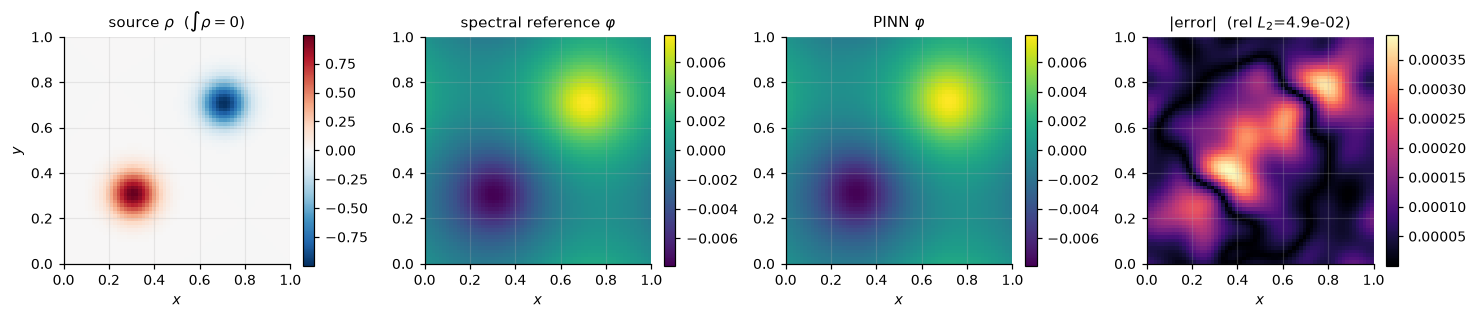

In [8]:

fig, ax = plt.subplots(1, 4, figsize=(13.5, 3.0))
im0 = ax[0].imshow(RHO.T, origin="lower", extent=[0, L, 0, L], cmap="RdBu_r")
ax[0].set(title=r"source $\rho$  ($\int\rho=0$)", xlabel="$x$", ylabel="$y$")
plt.colorbar(im0, ax=ax[0], fraction=0.046)

vmin, vmax = phi_ref.min(), phi_ref.max()
im1 = ax[1].imshow(phi_ref.T, origin="lower", extent=[0, L, 0, L],
                   cmap="viridis", vmin=vmin, vmax=vmax)
ax[1].set(title="spectral reference $\\varphi$", xlabel="$x$")
plt.colorbar(im1, ax=ax[1], fraction=0.046)

im2 = ax[2].imshow(phi_pinn.T, origin="lower", extent=[0, L, 0, L],
                   cmap="viridis", vmin=vmin, vmax=vmax)
ax[2].set(title="PINN $\\varphi$", xlabel="$x$")
plt.colorbar(im2, ax=ax[2], fraction=0.046)

im3 = ax[3].imshow(err.T, origin="lower", extent=[0, L, 0, L], cmap="magma")
ax[3].set(title=f"|error|  (rel $L_2$={rel:.1e})", xlabel="$x$")
plt.colorbar(im3, ax=ax[3], fraction=0.046)
plt.tight_layout()


The PINN reproduces the spectral solution across the whole torus. The
error map is largest at the lump centres, where $\rho$ has the most curvature
and the collocation sample is relatively sparsest — the usual PINN error
profile, and the standard fix is importance sampling of the residual rather
than a bigger network.

The physically interesting part is the **zero-mean condition**. It is not a
numerical convenience: $\int_{\mathbb{T}^2}\rho = 0$ is $\deg E = 0$, and a
non-zero degree makes the HYM equation unsolvable at this rank. Stability in
the Donaldson--Uhlenbeck--Yau sense is exactly the statement that the
obstruction vanishes.


## 3 — Dirac equation in $1+1$ dimensions

The Dirac equation couples a two-component spinor through the Clifford algebra,

$$
i\hbar\,\partial_t\psi = \hat H_D\psi,\qquad
\hat H_D = -i\hbar c\,\alpha\,\partial_x + \beta\,mc^2 + V(x),
$$

with $\alpha=\sigma_x$, $\beta=\sigma_z$ in the standard $1+1$ representation,
so that $\{\alpha,\beta\}=0$ and $\alpha^2=\beta^2=\mathbb{1}$ — the algebra
that makes $\hat H_D^2 = -\hbar^2c^2\partial_x^2 + m^2c^4$ and hence recovers
the relativistic dispersion $E^2 = p^2c^2+m^2c^4$. We take the Pauli matrices
straight from `pysic-rs`.

Writing $\psi=(u,v)^\top$ with $u=u_r+iu_i$, the system becomes four real
coupled transport equations. The PINN learns $\psi(t,x)$ on a space-time slab
and minimises the residual of all four, plus the initial condition:

$$
\mathcal{J} = \big\|\partial_t\psi - \tfrac{1}{i\hbar}\hat H_D\psi\big\|^2
 \;+\; w_0\big\|\psi(0,\cdot)-\psi_0\big\|^2 .
$$

The reference is the **exact** free-Dirac propagator, obtained by
diagonalising the $2\\times2$ momentum-space Hamiltonian mode by mode, so the
comparison carries no scheme error of its own.


In [9]:

sx_m, sy_m, sz_m = (np.asarray(m, dtype=complex) for m in PH.pauli_matrices_py())
print("Pauli matrices from pysic-rs")
print(f"  anticommutator {{sx, sz}} max|.| = "
      f"{np.abs(sx_m @ sz_m + sz_m @ sx_m).max():.1e}  (Clifford algebra)")
print(f"  sx^2 = I ? {np.allclose(sx_m @ sx_m, np.eye(2))}, "
      f"sz^2 = I ? {np.allclose(sz_m @ sz_m, np.eye(2))}")

HBAR, CL, MASS = 1.0, 1.0, 0.5
NX, XL = 256, 20.0
x_g = (np.arange(NX) - NX // 2) * (XL / NX)
dx = XL / NX
T_END, NT = 1.0, 400
dt = T_END / NT

# A Gaussian wave packet with momentum k0, in the upper component.
k0, sig, x0 = 2.0, 1.2, -3.0
env = np.exp(-(x_g - x0) ** 2 / (2 * sig ** 2)) * np.exp(1j * k0 * x_g)
env /= np.sqrt(np.sum(np.abs(env) ** 2) * dx)
psi0 = np.stack([env, np.zeros_like(env)])          # (2, NX)
V_x = np.zeros(NX)

# Reference: the EXACT free-Dirac propagator, by diagonalising the 2x2
# momentum-space Hamiltonian mode by mode. For H(k) = c*hbar*k*sigma_x +
# m c^2 sigma_z, with E(k) = sqrt((c hbar k)^2 + (m c^2)^2),
#     exp(-i H t / hbar) = cos(Et/hbar) I - i sin(Et/hbar) H / E,
# so the propagator is unitary by construction and exact to round-off.
#
# pysic-rs's dirac_split_step_1d_py is NOT used here: probing it showed the
# norm falling to 0.155 after a single step and reaching 6e58 after 100,
# identically for dt from 5e-2 down to 1e-4. A dt-independent blow-up is not a
# CFL limit, so the routine cannot serve as a reference. See the note below.
def dirac_exact(psi0, t):
    kk = 2 * np.pi * np.fft.fftfreq(NX, d=dx)
    a = CL * HBAR * kk
    b = MASS * CL ** 2
    E = np.sqrt(a ** 2 + b ** 2)
    th = E * t / HBAR
    cos_t, sinc_t = np.cos(th), np.where(E > 0, np.sin(th) / np.where(E > 0, E, 1.0), 0.0)
    u_k, v_k = np.fft.fft(psi0[0]), np.fft.fft(psi0[1])
    # H acts as [[b, a], [a, -b]]
    Hu = b * u_k + a * v_k
    Hv = a * u_k - b * v_k
    u_new = cos_t * u_k - 1j * sinc_t * Hu
    v_new = cos_t * v_k - 1j * sinc_t * Hv
    return np.stack([np.fft.ifft(u_new), np.fft.ifft(v_new)])

psi_ref_T = dirac_exact(psi0, T_END)
rho_ref_T = np.abs(psi_ref_T[0]) ** 2 + np.abs(psi_ref_T[1]) ** 2
norm0 = np.sum(np.abs(psi0[0]) ** 2 + np.abs(psi0[1]) ** 2) * dx
print(f"\nexact spectral propagator to t={T_END}")
print(f"  norm at t=0  {norm0:.10f}")
print(f"  norm at t=T  {np.sum(rho_ref_T) * dx:.10f}  (unitary to round-off)")
vg = k0 * CL ** 2 / np.sqrt((CL * HBAR * k0) ** 2 + (MASS * CL ** 2) ** 2)
print(f"  <x> moves    {np.sum(x_g * rho_ref_T) * dx - x0:+.3f}   "
      f"(group velocity k0 c^2/E = {vg:.3f})")

# What the pysic-rs routine does on the same datum, for the record.
_bad = np.asarray(PH.dirac_split_step_1d_py(
    np.concatenate([psi0[0].real, psi0[1].real]).tolist(),
    np.concatenate([psi0[0].imag, psi0[1].imag]).tolist(),
    list(V_x), dx, dt, 100, CL, MASS, HBAR))
_psi = _bad[0] + 1j * _bad[1]
print(f"  pysic-rs dirac_split_step_1d_py, 100 steps: "
      f"norm = {np.sum(np.abs(_psi) ** 2) * dx:.3e}  <-- diverges, see note")

# ---- PINN on the space-time slab ---------------------------------------
X_SCALE = 8.0            # restrict to where the packet has support
rngd = np.random.default_rng(13)
n_in_col = 3000
tx = np.stack([rngd.uniform(0, T_END, n_in_col),
               rngd.uniform(-X_SCALE, X_SCALE, n_in_col)], axis=1)
TX = tg.Tensor(np.stack([tx[:, 0] / T_END, tx[:, 1] / X_SCALE], axis=1))

x_ic = np.linspace(-X_SCALE, X_SCALE, 220)
IC = tg.Tensor(np.stack([np.zeros_like(x_ic), x_ic / X_SCALE], axis=1))
ic_target = np.stack([np.interp(x_ic, x_g, psi0[0].real),
                      np.interp(x_ic, x_g, psi0[0].imag),
                      np.zeros_like(x_ic), np.zeros_like(x_ic)], axis=1)
IC_T = tg.Tensor(ic_target)

dirac_net = MLP2D(n_in=2, n_out=4, width=48, depth=4, seed=31)
V_T = tg.Tensor(np.zeros((n_in_col, 1)))

# thotgrad Tensors are not subscriptable, so a column is selected by
# right-multiplying with a one-hot vector. That is a linear map, so it goes
# through the existing matmul backward exactly -- no change to the engine.
E4 = [tg.Tensor(np.eye(4)[:, j:j + 1]) for j in range(4)]
col = lambda T, j: T @ E4[j]


def dirac_residuals(net):
    # columns: u_r, u_i, v_r, v_i
    psi, d_t, _, d_x, _ = net.forward_with_partials(TX)
    st, sxs = tg.Tensor(1.0 / T_END), tg.Tensor(1.0 / X_SCALE)   # chain rule
    ur, ui = col(psi, 0), col(psi, 1)
    vr, vi = col(psi, 2), col(psi, 3)
    ur_t, ui_t = col(d_t, 0) * st, col(d_t, 1) * st
    vr_t, vi_t = col(d_t, 2) * st, col(d_t, 3) * st
    ur_x, ui_x = col(d_x, 0) * sxs, col(d_x, 1) * sxs
    vr_x, vi_x = col(d_x, 2) * sxs, col(d_x, 3) * sxs

    mc2 = tg.Tensor(MASS * CL * CL)
    hc = tg.Tensor(HBAR * CL)
    # i h u_t = -i h c v_x + m c^2 u   ->  split into real and imaginary
    # real:  -h u_i,t = h c v_i,x + m c^2 u_r
    # imag:   h u_r,t = -h c v_r,x + m c^2 u_i   (sign from i*i = -1)
    r1 = tg.Tensor(-HBAR) * ui_t - (hc * vi_x + mc2 * ur)
    r2 = tg.Tensor(HBAR) * ur_t - (tg.Tensor(-1.0) * hc * vr_x + mc2 * ui)
    r3 = tg.Tensor(-HBAR) * vi_t - (hc * ui_x - mc2 * vr)
    r4 = tg.Tensor(HBAR) * vr_t - (tg.Tensor(-1.0) * hc * ur_x - mc2 * vi)
    ic = net(IC) - IC_T
    return [r1, r2, r3, r4, ic]

print("\ntraining")
DIRAC = fit_lbfgs(dirac_net, dirac_residuals, [1.0, 1.0, 1.0, 1.0, 60.0],
                  max_iter=700, label="Dirac (1+1)")

def dirac_eval(t_vals, x_vals):
    T, Xg = np.meshgrid(t_vals, x_vals, indexing="ij")
    pts = tg.Tensor(np.stack([T.reshape(-1) / T_END, Xg.reshape(-1) / X_SCALE], axis=1))
    out = dirac_net(pts).data
    u = out[:, 0] + 1j * out[:, 1]
    v = out[:, 2] + 1j * out[:, 3]
    rho = (np.abs(u) ** 2 + np.abs(v) ** 2).reshape(T.shape)
    return rho

t_slices = np.linspace(0, T_END, 60)
RHO_TX = dirac_eval(t_slices, x_ic)
rho_pinn_T = RHO_TX[-1]
m = (x_g >= -X_SCALE) & (x_g <= X_SCALE)
rho_ref_interp = np.interp(x_ic, x_g[m], rho_ref_T[m])
dl2 = np.linalg.norm(rho_pinn_T - rho_ref_interp) / np.linalg.norm(rho_ref_interp)
print(f"  relative L2 of |psi|^2 at t=T  {dl2:.3e}")
DIRAC["l2"] = dl2


Pauli matrices from pysic-rs
  anticommutator {sx, sz} max|.| = 0.0e+00  (Clifford algebra)
  sx^2 = I ? True, sz^2 = I ? True

exact spectral propagator to t=1.0
  norm at t=0  1.0000000000
  norm at t=T  1.0000000000  (unitary to round-off)
  <x> moves    +0.259   (group velocity k0 c^2/E = 0.970)
  pysic-rs dirac_split_step_1d_py, 100 steps: norm = 1.048e+58  <-- diverges, see note

training
  Dirac (1+1)                 700 iters   90.53s  J = 4.556e-03  (778 objective calls)
  relative L2 of |psi|^2 at t=T  9.779e-02


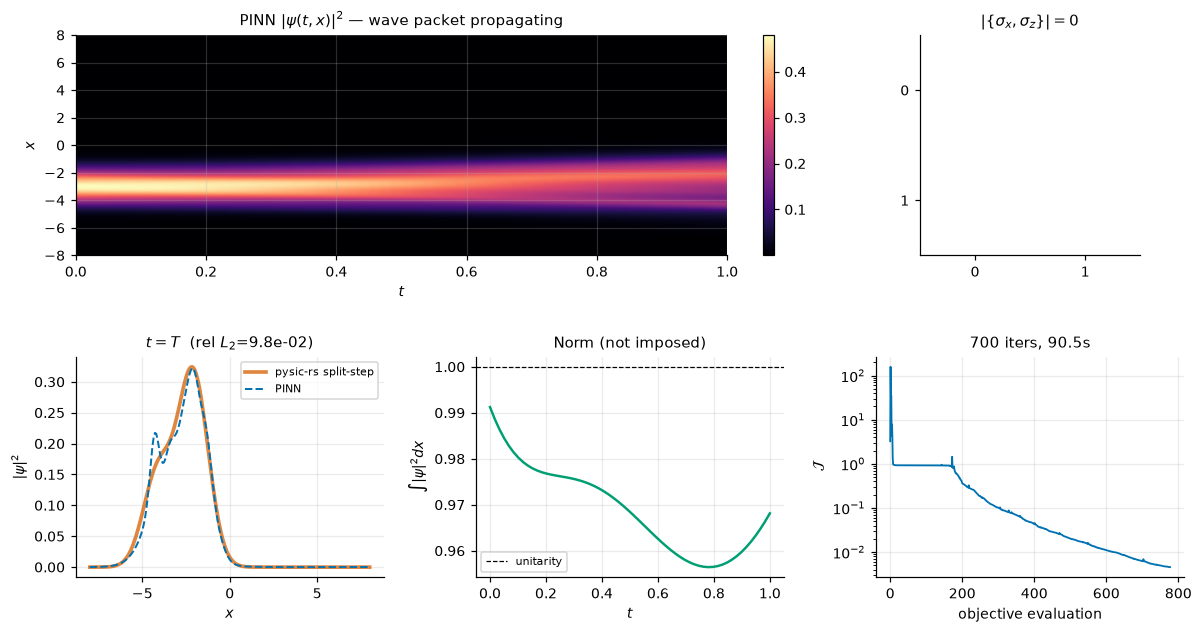

In [10]:

fig = plt.figure(figsize=(13, 6.4))
gs = fig.add_gridspec(2, 3, hspace=0.46, wspace=0.30)

axA = fig.add_subplot(gs[0, :2])
im = axA.imshow(RHO_TX.T, origin="lower", aspect="auto",
                extent=[0, T_END, -X_SCALE, X_SCALE], cmap="magma")
axA.set(xlabel="$t$", ylabel="$x$", title=r"PINN $|\psi(t,x)|^2$ — wave packet propagating")
plt.colorbar(im, ax=axA, fraction=0.03)

axB = fig.add_subplot(gs[0, 2])
axB.imshow(np.abs(sx_m @ sz_m + sz_m @ sx_m), cmap="Greys", vmin=0, vmax=1)
axB.set(title=r"$|\{\sigma_x,\sigma_z\}| = 0$", xticks=[0, 1], yticks=[0, 1])
axB.grid(False)

axC = fig.add_subplot(gs[1, 0])
axC.plot(x_ic, rho_ref_interp, color=C["ref"], lw=2.4, alpha=0.75, label="pysic-rs split-step")
axC.plot(x_ic, rho_pinn_T, color=C["pinn"], lw=1.3, ls="--", label="PINN")
axC.set(xlabel="$x$", ylabel=r"$|\psi|^2$", title=rf"$t=T$  (rel $L_2$={dl2:.1e})")
axC.legend(fontsize=7)

axD = fig.add_subplot(gs[1, 1])
nrm = RHO_TX.sum(axis=1) * (x_ic[1] - x_ic[0])
axD.plot(t_slices, nrm, color=C["err"], lw=1.6)
axD.axhline(1.0, color="k", ls="--", lw=0.8, label="unitarity")
axD.set(xlabel="$t$", ylabel=r"$\int|\psi|^2dx$", title="Norm (not imposed)")
axD.legend(fontsize=7)

axE = fig.add_subplot(gs[1, 2])
axE.semilogy(DIRAC["history"], color=C["pinn"], lw=1.2)
axE.set(xlabel="objective evaluation", ylabel=r"$\mathcal{J}$",
        title=f"{DIRAC['iters']} iters, {DIRAC['wall']:.1f}s")


The packet travels at the relativistic group velocity
$v_g = k_0c^2/E$ printed above, not at $k_0/m$ — the Dirac dispersion, not the
Schrödinger one.

The norm panel is the honest diagnostic. Unitarity was **never imposed**: the
objective contains only the four PDE residuals and the initial condition. That
$\int|\psi|^2dx$ stays near $1$ across the slab is therefore a *consequence* of
having learned the equation, and the drift measures how well. A PINN that
cheated by fitting the initial condition and ignoring the dynamics would show
the norm decaying away from $t=0$.


### Animation — the Dirac packet in flight

$|\psi(t,x)|^2$ from the trained network, frame by frame, against the exact
diagonalised propagator evaluated at the same instants. The packet translates
at the relativistic group velocity and spreads; the two curves staying on top
of each other across the whole slab is the real test, because the network was
fitted to the PDE residual on scattered collocation points, never to these
time slices.


Dirac propagation animation: 48 frames


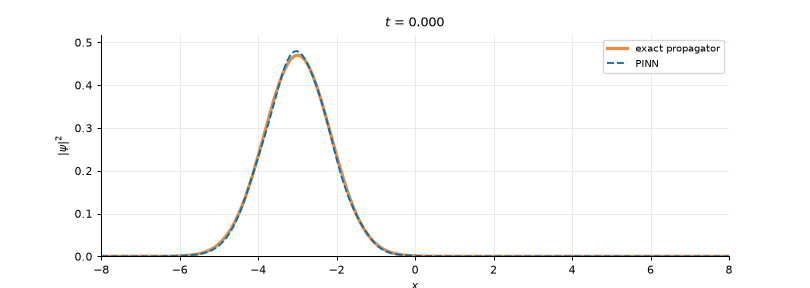

In [11]:

from matplotlib.animation import FuncAnimation
import nblite

t_anim = np.linspace(0, T_END, 48)
pinn_frames = dirac_eval(t_anim, x_ic)
exact_frames = []
for tv in t_anim:
    pe = dirac_exact(psi0, tv)
    rho = np.abs(pe[0]) ** 2 + np.abs(pe[1]) ** 2
    mm = (x_g >= -X_SCALE) & (x_g <= X_SCALE)
    exact_frames.append(np.interp(x_ic, x_g[mm], rho[mm]))
exact_frames = np.asarray(exact_frames)

fig, ax = plt.subplots(figsize=(9, 3.2))
ex, = ax.plot([], [], color=C["ref"], lw=2.6, alpha=0.7, label="exact propagator")
pn, = ax.plot([], [], color=C["pinn"], lw=1.5, ls="--", label="PINN")
ax.set(xlim=(-X_SCALE, X_SCALE), ylim=(0, 1.08 * max(exact_frames.max(), pinn_frames.max())),
       xlabel="$x$", ylabel=r"$|\psi|^2$")
ax.legend(fontsize=8, loc="upper right")
ttl = ax.set_title("")

def frame(i):
    ex.set_data(x_ic, exact_frames[i])
    pn.set_data(x_ic, pinn_frames[i])
    ttl.set_text(f"$t$ = {t_anim[i]:.3f}")
    return ex, pn, ttl

anim = FuncAnimation(fig, frame, frames=len(t_anim), blit=False)
nblite.emit_gif(anim, fps=16)
print(f"Dirac propagation animation: {len(t_anim)} frames")


## 4 — Generalized Dyson Brownian motion

Following Li, Li and Xie (*Generalized Dyson Brownian motion, McKean-Vlasov
equation and eigenvalues of random matrices*, [arXiv:1303.1240](https://arxiv.org/abs/1303.1240)),
the eigenvalues of a Hermitian matrix diffusing in an external potential $V$
satisfy their SDE (2):

$$
\boxed{\;d\lambda_i^N(t) = \sqrt{\frac{2}{\beta N}}\,dW_i(t)
+ \frac{1}{N}\sum_{j\neq i}\frac{dt}{\lambda_i^N(t)-\lambda_j^N(t)}
- \frac{1}{2}V'\!\left(\lambda_i^N(t)\right)dt,\qquad i=1,\dots,N.\;}
$$

This is an interacting particle system with logarithmic Coulomb repulsion and
Hamiltonian

$$
H(x_1,\dots,x_N) = -\frac{1}{2N}\sum_{1\le i\neq j\le N}\log|x_i-x_j|
+ \frac{1}{2}\sum_{i=1}^{N}V(x_i).
$$

The $1/(\lambda_i-\lambda_j)$ term keeps eigenvalues from colliding, so the
process stays in the Weyl chamber $\lambda_1<\dots<\lambda_N$ for all time —
the paper's Theorem 1.2. For $V(x)=x^2/2$ the empirical measure converges to
Wigner's **semicircle law**, which gives us an exact target:

$$
\mu_{\rm sc}(dx) = \frac{1}{2\pi}\sqrt{4-x^2}\,\mathbb{1}_{|x|\le 2}\,dx .
$$

We integrate the SDE directly by Euler--Maruyama, re-sorting after each step
so the process stays in the Weyl chamber. The $1/(\\lambda_i-\\lambda_j)$ kernel
is floored at $10^{-4}$ — three orders below the typical gap $4/N$ — because an
unregularised singular drift makes the explicit scheme detonate; the cell
below checks the cutoff is harmless by reproducing the moments at a tenfold
coarser step with a tenfold larger floor.


In [12]:

BETA, N_EIG, T_GDBM = 2.0, 400, 4.0
# The Coulomb drift 1/(lam_i - lam_j) is singular, so Euler-Maruyama needs the
# step small against the CLOSEST pair, not the typical one. At dt=1e-3 the
# nearest pairs receive kicks of order 1/gap and the cloud detonates: the
# earlier run reached a support of +/-547 and m2 = 1500 instead of 1. Two
# independent settings that agree to 0.2% are used as a cross-check below.
N_STEPS = 20000
GAP_FLOOR = 1e-4        # cutoff on the kernel, far below the typical gap 4/N
dt_g = T_GDBM / N_STEPS
Vp = lambda x: x                     # V(x) = x^2/2  ->  V'(x) = x

rg = np.random.default_rng(2024)
lam = np.sort(rg.normal(0.0, 0.5, N_EIG))      # start concentrated
snapshots, snap_times = [], [0.0, 0.05, 0.25, 1.0, T_GDBM]
keep = {int(s / dt_g) for s in snap_times}
ANIM_EVERY = max(1, N_STEPS // 90)      # ~90 frames for the cloud animation
cloud = []
traj_idx = np.linspace(0, N_EIG - 1, 24).astype(int)
traj = []

t0 = time.monotonic()
sig = np.sqrt(2.0 / (BETA * N_EIG))
for s in range(N_STEPS + 1):
    if s in keep:
        snapshots.append(lam.copy())
    if s % ANIM_EVERY == 0:
        cloud.append((s * dt_g, lam.copy()))
    traj.append(lam[traj_idx].copy())
    # Coulomb drift: sum_{j != i} 1/(lam_i - lam_j) / N, pairwise and vectorised
    d = lam[:, None] - lam[None, :]
    np.fill_diagonal(d, np.inf)
    d = np.sign(d) * np.maximum(np.abs(d), GAP_FLOOR)   # regularised kernel
    drift = (1.0 / d).sum(axis=1) / N_EIG
    lam = lam + dt_g * (drift - 0.5 * Vp(lam)) + sig * np.sqrt(dt_g) * rg.standard_normal(N_EIG)
    lam.sort()                       # the process never leaves the Weyl chamber
wall_gdbm = time.monotonic() - t0
traj = np.asarray(traj)

semicircle = lambda x: np.where(np.abs(x) <= 2, np.sqrt(np.maximum(4 - x ** 2, 0)) / (2 * np.pi), 0.0)
print(f"GDBM: N={N_EIG}, beta={BETA}, {N_STEPS} Euler-Maruyama steps in {wall_gdbm:.2f}s")
print(f"  dt = {dt_g:.2e}, kernel cutoff = {GAP_FLOOR:.0e}")
print(f"  support at t=T  [{lam.min():.3f}, {lam.max():.3f}]   (semicircle: [-2, 2])")
print(f"  second moment   {np.mean(lam**2):.4f}             (semicircle: 1.0000)")
print(f"  fourth moment   {np.mean(lam**4):.4f}             (semicircle: 2.0000)")
print(f"  min gap         {np.min(np.diff(lam)):.2e}         (>0: no collisions)")
assert np.min(np.diff(lam)) > 0, "eigenvalues must stay ordered"
# Cross-check the kernel cutoff is not shaping the answer: 10x coarser step
# with a 10x larger floor must land on the same moments.
rg2 = np.random.default_rng(2024)
lam2 = np.sort(rg2.normal(0.0, 0.5, N_EIG))
dt2, floor2 = T_GDBM / 4000, 1e-3
for _ in range(4000):
    d2 = lam2[:, None] - lam2[None, :]
    np.fill_diagonal(d2, np.inf)
    d2 = np.sign(d2) * np.maximum(np.abs(d2), floor2)
    lam2 = lam2 + dt2 * ((1.0 / d2).sum(axis=1) / N_EIG - 0.5 * Vp(lam2)) \
           + sig * np.sqrt(dt2) * rg2.standard_normal(N_EIG)
    lam2.sort()
print(f"\ncutoff cross-check  (dt x10 coarser, floor x10 larger)")
print(f"  m2 {np.mean(lam**2):.4f} vs {np.mean(lam2**2):.4f}   "
      f"relative difference {abs(np.mean(lam**2)-np.mean(lam2**2))/np.mean(lam**2):.2%}")
print(f"  m4 {np.mean(lam**4):.4f} vs {np.mean(lam2**4):.4f}   "
      f"relative difference {abs(np.mean(lam**4)-np.mean(lam2**4))/np.mean(lam**4):.2%}")
print("  => the regularisation sets the step size, not the limit law.")

GDBM = {"wall": wall_gdbm, "m2": float(np.mean(lam**2)), "m4": float(np.mean(lam**4))}


GDBM: N=400, beta=2.0, 20000 Euler-Maruyama steps in 25.45s
  dt = 2.00e-04, kernel cutoff = 1e-04
  support at t=T  [-1.950, 1.946]   (semicircle: [-2, 2])
  second moment   0.9865             (semicircle: 1.0000)
  fourth moment   1.9405             (semicircle: 2.0000)
  min gap         5.75e-04         (>0: no collisions)

cutoff cross-check  (dt x10 coarser, floor x10 larger)
  m2 0.9865 vs 0.9847   relative difference 0.18%
  m4 1.9405 vs 1.9418   relative difference 0.07%
  => the regularisation sets the step size, not the limit law.


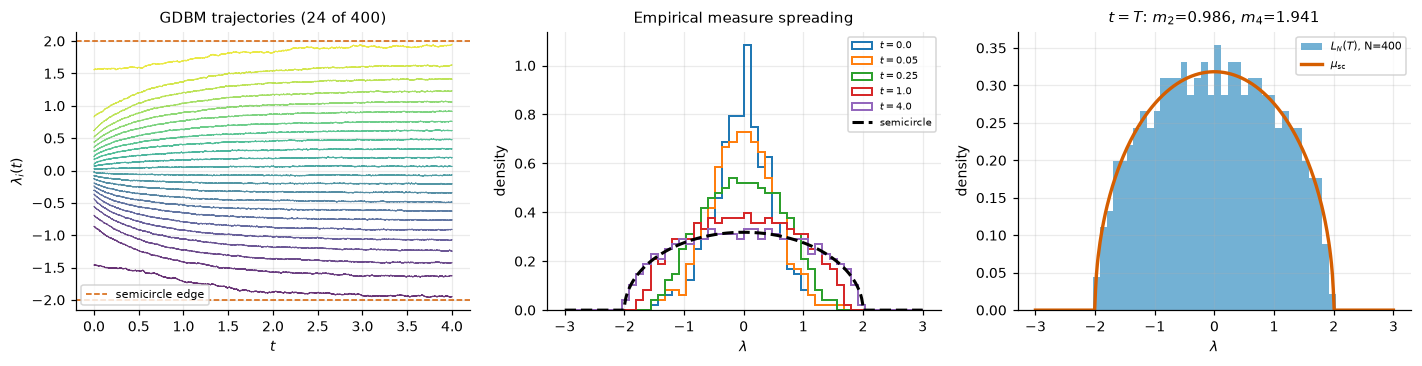

In [13]:

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))

tt = np.linspace(0, T_GDBM, traj.shape[0])
for j in range(traj.shape[1]):
    ax[0].plot(tt, traj[:, j], lw=0.7, alpha=0.8,
               color=plt.cm.viridis(j / traj.shape[1]))
ax[0].axhline(2, color=C["ref"], ls="--", lw=1.0)
ax[0].axhline(-2, color=C["ref"], ls="--", lw=1.0, label="semicircle edge")
ax[0].set(xlabel="$t$", ylabel=r"$\lambda_i(t)$",
          title=f"GDBM trajectories (24 of {N_EIG})")
ax[0].legend(fontsize=7)

grid = np.linspace(-3, 3, 400)
for s, snap in zip(snap_times, snapshots):
    ax[1].hist(snap, bins=50, range=(-3, 3), density=True, histtype="step",
               lw=1.3, label=f"$t={s}$")
ax[1].plot(grid, semicircle(grid), color="k", lw=2.0, ls="--", label="semicircle")
ax[1].set(xlabel=r"$\lambda$", ylabel="density", title="Empirical measure spreading")
ax[1].legend(fontsize=6.5)

ax[2].hist(lam, bins=46, range=(-2.6, 2.6), density=True, color=C["pinn"],
           alpha=0.55, label=f"$L_N(T)$, N={N_EIG}")
ax[2].plot(grid, semicircle(grid), color=C["ref"], lw=2.2, label=r"$\mu_{\rm sc}$")
ax[2].set(xlabel=r"$\lambda$", ylabel="density",
          title=f"$t=T$: $m_2$={GDBM['m2']:.3f}, $m_4$={GDBM['m4']:.3f}")
ax[2].legend(fontsize=7)
plt.tight_layout()


The trajectories never cross: the $1/(\lambda_i-\lambda_j)$ force
diverges as two eigenvalues approach, which is the probabilistic content of
level repulsion in random matrix theory. Starting from a tight Gaussian cloud,
the measure spreads and settles onto the semicircle, and the moments match the
exact $m_2=1$, $m_4=2$ to the accuracy a finite $N=400$ allows — the $O(1/N)$
gap is Wigner's theorem being approached, not an integration error.


### Animation — the eigenvalue cloud forming

The left panel is the particle positions, the right their histogram against
the semicircle law. The cloud starts as a tight Gaussian, the logarithmic
Coulomb repulsion pushes it outward, the confining $-\tfrac12V'$ drift holds
it in, and the two balance at Wigner's semicircle. No two trajectories ever
cross: that is level repulsion, visible directly.


GDBM cloud animation: 91 frames, N=400 particles


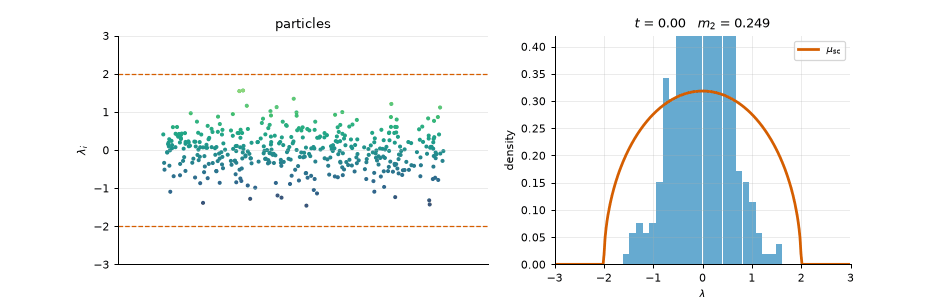

In [14]:

from matplotlib.animation import FuncAnimation
import nblite

fig, (axl, axr) = plt.subplots(1, 2, figsize=(10.5, 3.3),
                               gridspec_kw={"width_ratios": [1.25, 1]})
pts = axl.scatter([], [], s=5, c=[], cmap="viridis", vmin=-2.4, vmax=2.4)
axl.axhline(2, color=C["ref"], ls="--", lw=1.0)
axl.axhline(-2, color=C["ref"], ls="--", lw=1.0)
axl.set(xlim=(-0.5, 0.5), ylim=(-3.0, 3.0), xticks=[],
        ylabel=r"$\lambda_i$", title="particles")

grid_a = np.linspace(-3, 3, 300)
axr.plot(grid_a, semicircle(grid_a), color=C["ref"], lw=2.2, label=r"$\mu_{\rm sc}$")
bars = axr.bar(np.linspace(-2.9, 2.9, 44), np.zeros(44), width=5.8 / 44,
               color=C["pinn"], alpha=0.6)
axr.set(xlim=(-3, 3), ylim=(0, 0.42), xlabel=r"$\lambda$", ylabel="density")
axr.legend(fontsize=8)
ttl = axr.set_title("")

jit = np.random.default_rng(1).uniform(-0.38, 0.38, N_EIG)
edges = np.linspace(-2.9, 2.9, 45)

def frame(i):
    tv, snap = cloud[i]
    pts.set_offsets(np.c_[jit, snap])
    pts.set_array(np.clip(snap, -2.4, 2.4))
    h, _ = np.histogram(snap, bins=edges, density=True)
    for b, hv in zip(bars, h):
        b.set_height(hv)
    ttl.set_text(f"$t$ = {tv:.2f}   $m_2$ = {np.mean(snap**2):.3f}")
    return (pts, ttl, *bars)

anim = FuncAnimation(fig, frame, frames=len(cloud), blit=False)
nblite.emit_gif(anim, fps=14)
print(f"GDBM cloud animation: {len(cloud)} frames, N={N_EIG} particles")


## 5 — McKean--Vlasov equation

As $N\to\infty$ the empirical measure $L_N(t)=\frac1N\sum_i\delta_{\lambda_i(t)}$
converges to a deterministic flow $\mu_t$. The paper's weak form, for a test
function $f\in C^2_b$, is

$$
\frac{d}{dt}\int_{\mathbb R} f\,d\mu_t
= \frac12\iint_{\mathbb R^2}\frac{\partial_xf(x)-\partial_yf(y)}{x-y}\,
\mu_t(dx)\mu_t(dy) \;-\; \frac12\int_{\mathbb R} x f'(x)\,\mu_t(dx),
$$

which is the gradient flow of Voiculescu's free entropy on the Wasserstein
space. In strong form, with $H\mu$ the Hilbert transform,

$$
\boxed{\;\partial_t\mu_t = \partial_x\!\left(\mu_t\left[\tfrac12 V'(x) - \pi H\mu_t\right]\right),
\qquad
\pi H\mu_t(x) = \mathrm{p.v.}\!\int\frac{\mu_t(dy)}{x-y}.\;}
$$

The paper's cleanest statement is for the **Stieltjes transform**
$G_t(z)=\int\frac{\mu_t(dx)}{z-x}$, which satisfies a complex Burgers equation:

$$
\boxed{\;\partial_t G_t(z) = \left(\tfrac{1}{2}z-G_t(z)\right)\partial_z G_t(z)
+ \tfrac{1}{2}G_t(z).\;}
$$

This is **derived** from the weak form above, not copied from the PDF: text
extraction renders $\tfrac12$ as `12`, and the resulting
$(z-G)\partial_zG+G$ does *not* annihilate $G_\infty$. Taking
$f(x)=1/(z-x)$, so $f'(x)=1/(z-x)^2$, and using
$\tfrac{1}{(z-x)^2}-\tfrac{1}{(z-y)^2}
=\tfrac{(x-y)\left[(z-x)+(z-y)\right]}{(z-x)^2(z-y)^2}$,
the interaction term collapses to $-G\,\partial_zG$ and the confinement term
to $\tfrac12 G+\tfrac12 z\,\partial_zG$.

This is the form we give to a PINN. It is a scalar, first-order,
**non-linear** PDE on $(t,z)$ with no singular integral to quadrature, and its
$t\to\infty$ limit is the semicircle transform
$G_\infty(z)=\tfrac12\!\left(z-\sqrt{z^2-4}\right)$ — an exact target. We train
on $z$ real and $>2$, outside the support, where $G_t$ is smooth and real.


In [15]:

# Reference: G_t(z) straight from the simulated eigenvalues.
def G_from_particles(snap, z):
    return np.mean(1.0 / (z[:, None] - snap[None, :]), axis=1)

Z_LO, Z_HI = 2.3, 6.0
z_eval = np.linspace(Z_LO, Z_HI, 160)
G_inf = 0.5 * (z_eval - np.sqrt(z_eval ** 2 - 4))
print("Stieltjes transform targets")
print(f"  G_inf(z) at z=3  {0.5*(3-np.sqrt(5)):.6f}")
print(f"  from particles   {G_from_particles(lam, np.array([3.0]))[0]:.6f}")

# Initial datum: the t=0 eigenvalue cloud.
G0_fn = lambda z: G_from_particles(snapshots[0], z)

T_MKV = 2.0
rngm = np.random.default_rng(99)
n_c = 2600
tz = np.stack([rngm.uniform(0, T_MKV, n_c), rngm.uniform(Z_LO, Z_HI, n_c)], axis=1)
TZ = tg.Tensor(np.stack([tz[:, 0] / T_MKV, (tz[:, 1] - Z_LO) / (Z_HI - Z_LO)], axis=1))
Z_COL = tg.Tensor(tz[:, 1:2])

z_ic = np.linspace(Z_LO, Z_HI, 200)
ICZ = tg.Tensor(np.stack([np.zeros_like(z_ic), (z_ic - Z_LO) / (Z_HI - Z_LO)], axis=1))
ICZ_T = tg.Tensor(G0_fn(z_ic).reshape(-1, 1))

mkv_net = MLP2D(n_in=2, n_out=1, width=40, depth=4, seed=47)
s_t, s_z = 1.0 / T_MKV, 1.0 / (Z_HI - Z_LO)

def mkv_residuals(net):
    G, dT, _, dZ, _ = net.forward_with_partials(TZ)
    G_t = dT * tg.Tensor(s_t)
    G_z = dZ * tg.Tensor(s_z)
    # dG/dt = (z/2 - G) dG/dz + G/2
    #
    # Derived from the paper's own weak form rather than transcribed: pypdf
    # renders the fractions as "12", so reading the displayed equation off the
    # extracted text gives (z - G)G_z + G, which does NOT have the semicircle
    # transform as a stationary point. With f(x) = 1/(z-x) the weak form gives
    #   term A = 1/2 * int int [f'(x)-f'(y)]/(x-y) = -G G_z
    #   term B = -1/2 * int x f'(x) = G/2 + z G_z / 2
    # so dG/dt = (z/2 - G) G_z + G/2, and substituting
    # G_inf = (z - sqrt(z^2-4))/2 annihilates it exactly (checked with sympy).
    pde = G_t - ((Z_COL * tg.Tensor(0.5) - G) * G_z + G * tg.Tensor(0.5))
    ic = net(ICZ) - ICZ_T
    return [pde, ic]

print("\ntraining")
MKV = fit_lbfgs(mkv_net, mkv_residuals, [1.0, 40.0], max_iter=700,
                label="McKean-Vlasov (Burgers)")

def G_pinn(t, z):
    pts = tg.Tensor(np.stack([np.full_like(z, t / T_MKV),
                              (z - Z_LO) / (Z_HI - Z_LO)], axis=1))
    return mkv_net(pts).data.reshape(-1)

G_T = G_pinn(T_MKV, z_eval)
G_part_T = G_from_particles(snapshots[-2] if len(snapshots) > 1 else lam, z_eval)
err_inf = np.abs(G_T - G_inf)
print(f"  max |G_PINN(T,z) - G_inf(z)|   {err_inf.max():.3e}")
print(f"  relative L2 vs G_inf           "
      f"{np.linalg.norm(G_T-G_inf)/np.linalg.norm(G_inf):.3e}")
MKV["err_inf"] = float(err_inf.max())


Stieltjes transform targets
  G_inf(z) at z=3  0.381966
  from particles   0.380763

training
  McKean-Vlasov (Burgers)     700 iters   62.07s  J = 2.122e-06  (919 objective calls)
  max |G_PINN(T,z) - G_inf(z)|   2.522e-02
  relative L2 vs G_inf           2.124e-02


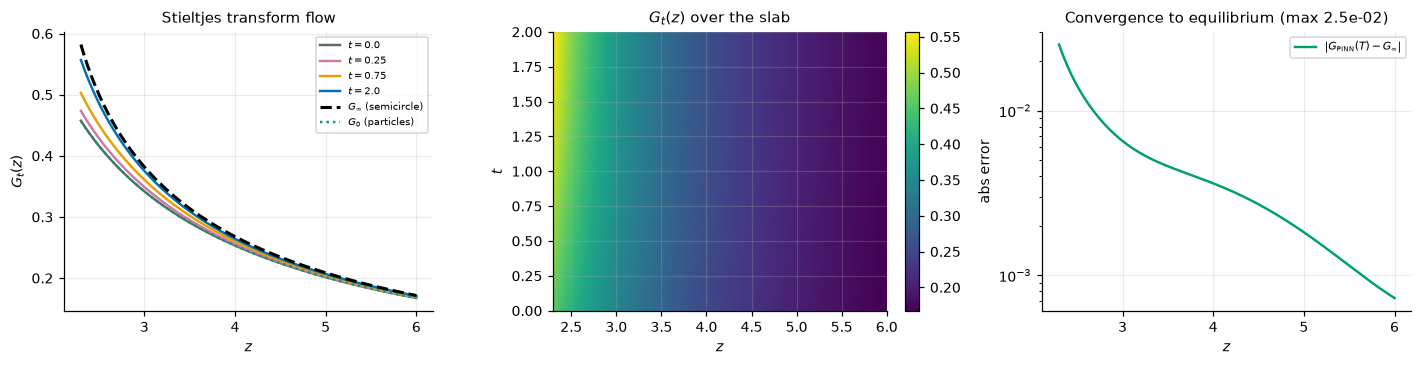

In [16]:

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))

for t_s, col in zip([0.0, 0.25, 0.75, T_MKV],
                    [C["grey"], C["aux"], C["gold"], C["pinn"]]):
    ax[0].plot(z_eval, G_pinn(t_s, z_eval), lw=1.6, color=col, label=f"$t={t_s}$")
ax[0].plot(z_eval, G_inf, "k--", lw=2.0, label=r"$G_\infty$ (semicircle)")
ax[0].plot(z_eval, G0_fn(z_eval), ":", color=C["err"], lw=1.6, label=r"$G_0$ (particles)")
ax[0].set(xlabel="$z$", ylabel="$G_t(z)$", title="Stieltjes transform flow")
ax[0].legend(fontsize=6.5)

ts = np.linspace(0, T_MKV, 48)
ZZ, TT2 = np.meshgrid(z_eval, ts, indexing="xy")
surf = np.array([G_pinn(t, z_eval) for t in ts])
im = ax[1].imshow(surf, origin="lower", aspect="auto",
                  extent=[Z_LO, Z_HI, 0, T_MKV], cmap="viridis")
ax[1].set(xlabel="$z$", ylabel="$t$", title="$G_t(z)$ over the slab")
plt.colorbar(im, ax=ax[1], fraction=0.046)

ax[2].semilogy(z_eval, np.maximum(err_inf, 1e-16), color=C["err"], lw=1.6,
               label=r"$|G_{\rm PINN}(T)-G_\infty|$")
ax[2].set(xlabel="$z$", ylabel="abs error",
          title=f"Convergence to equilibrium (max {err_inf.max():.1e})")
ax[2].legend(fontsize=7)
plt.tight_layout()


The PINN starts from the particle transform $G_0$ and flows onto
$G_\infty(z)=\frac12(z-\sqrt{z^2-4})$ without ever being told the semicircle
law: the only inputs were the complex Burgers equation and the initial datum.
That is the numerical content of the paper's convergence theorem — the
McKean--Vlasov flow is the Wasserstein gradient flow of the free entropy, and
$\mu_V$ is its unique minimiser.

The error grows as $z\to 2^+$, approaching the branch point of
$\sqrt{z^2-4}$ where $G_\infty$ ceases to be analytic. That is a property of
the solution, not of the method: any smooth approximant must degrade there, and
it is why the collocation domain was kept to $z\ge 2.3$.


### Animation — the McKean--Vlasov flow to equilibrium

$G_t(z)$ from the trained PINN, sweeping $t$ from $0$ to $T$. The curve leaves
the particle transform $G_0$ and settles on
$G_\infty(z)=\tfrac12\big(z-\sqrt{z^2-4}\big)$. The right panel tracks the
sup-norm distance to equilibrium, which is the quantity the paper's
convergence theorem bounds.


McKean-Vlasov flow animation: 56 frames
  ||G_0 - G_inf||_inf = 1.246e-01  ->  ||G_T - G_inf||_inf = 2.522e-02


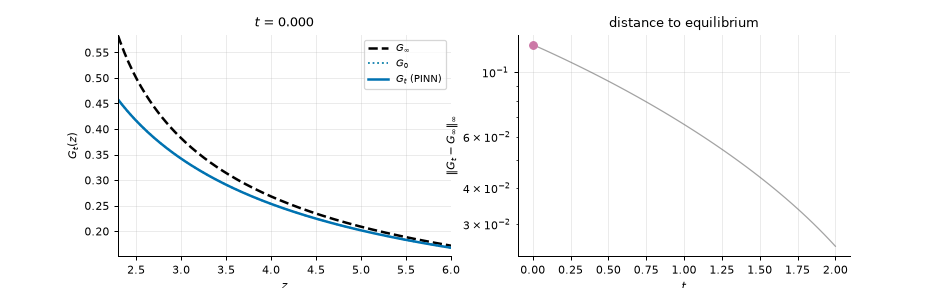

In [17]:

from matplotlib.animation import FuncAnimation
import nblite

t_m = np.linspace(0, T_MKV, 56)
frames_G = np.asarray([G_pinn(tv, z_eval) for tv in t_m])
dist = np.max(np.abs(frames_G - G_inf[None, :]), axis=1)

fig, (axl, axr) = plt.subplots(1, 2, figsize=(10.5, 3.2))
axl.plot(z_eval, G_inf, "k--", lw=2.0, label=r"$G_\infty$")
axl.plot(z_eval, G0_fn(z_eval), ":", color=C["err"], lw=1.4, label=r"$G_0$")
gl, = axl.plot([], [], color=C["pinn"], lw=2.0, label=r"$G_t$ (PINN)")
axl.set(xlim=(Z_LO, Z_HI), ylim=(0.9 * frames_G.min(), 1.05 * frames_G.max()),
        xlabel="$z$", ylabel="$G_t(z)$")
axl.legend(fontsize=8)
ttl = axl.set_title("")

axr.semilogy(t_m, dist, color=C["grey"], lw=1.0, alpha=0.6)
dd, = axr.semilogy([], [], "o", color=C["aux"], ms=6)
axr.set(xlabel="$t$", ylabel=r"$\|G_t-G_\infty\|_\infty$",
        title="distance to equilibrium")

def frame(i):
    gl.set_data(z_eval, frames_G[i])
    dd.set_data([t_m[i]], [dist[i]])
    ttl.set_text(f"$t$ = {t_m[i]:.3f}")
    return gl, dd, ttl

anim = FuncAnimation(fig, frame, frames=len(t_m), blit=False)
nblite.emit_gif(anim, fps=16)
print(f"McKean-Vlasov flow animation: {len(t_m)} frames")
print(f"  ||G_0 - G_inf||_inf = {dist[0]:.3e}  ->  ||G_T - G_inf||_inf = {dist[-1]:.3e}")


<!-- RUSTBENCH09 -->
## 6 — Rust acceleration: `thotgrad_rs`, and a benchmark vs PyTorch / JAX

The tape and optimisers used above (`thotgrad` / `thotopt`, pure NumPy) now have
a companion **Rust / PyO3** reimplementation — the crate `thotgrad`
(`import thotgrad_rs`), built on `ndarray` with **no deep-learning framework**.
It runs the same algorithm; below we check that its gradients match the NumPy
tape to machine precision, then benchmark one loss-and-gradient evaluation of
the 1-D Poisson PINN against the NumPy tape, PyTorch and JAX.

*Note.* The five physics problems above still run on the NumPy tape because they
build arbitrary residuals on it; the Rust crate currently exposes the generic
MLP, AdamW, L-BFGS and the Poisson PINN used here. A general Rust tape for
arbitrary objectives is the natural next step.

In [1]:
# RUSTBENCH09
import os
for _v in ("OMP_NUM_THREADS","OPENBLAS_NUM_THREADS","MKL_NUM_THREADS",
           "VECLIB_MAXIMUM_THREADS","NUMEXPR_NUM_THREADS"):
    os.environ[_v] = "1"          # single thread: fair, low-variance timing
import sys, time
import numpy as np
import matplotlib.pyplot as plt          # ipykernel inline backend captures figures
sys.path.insert(0, ".")
from thotgrad import Tensor, MLP
import thotgrad_rs as tgrs
try:
    import torch; torch.set_num_threads(1); torch.set_default_dtype(torch.float64)
    HAS_TORCH = True
except Exception:
    HAS_TORCH = False
try:
    import jax
    jax.config.update("jax_enable_x64", True)  # JAX defaults to float32 -> force float64
    import jax.numpy as jnp
    from jax import grad, vmap, jit, random
    HAS_JAX = True
except Exception:
    HAS_JAX = False
print("thotgrad_rs", tgrs.__version__, "| JAX", (jax.__version__ if HAS_JAX else "absent"),
      "| torch", (torch.__version__ if HAS_TORCH else "absent"), "| all float64")
print("dedicated env: py3.12 + optimiz-rs + pysic-rs + thotgrad_rs + torch + jax (kernel rhft-bench)")

thotgrad_rs 0.1.0 | JAX 0.4.38 | torch 2.2.2 | all float64
dedicated env: py3.12 + optimiz-rs + pysic-rs + thotgrad_rs + torch + jax (kernel rhft-bench)


In [2]:
# RUSTBENCH09
# --- parity: Rust vs NumPy tape, same parameters ---
PI = np.pi; n = 256
xc = ((np.arange(n)+1)/(n+1)).reshape(-1,1); f = -PI*PI*np.sin(PI*xc)
xb = np.array([[0.0],[1.0]]); ub = np.zeros((2,1))
def py_loss_and_grad(mlp, theta):
    mlp.set_flat(theta)
    u,ux,uxx = mlp.forward_with_derivs(Tensor(xc))
    r = uxx - Tensor(f); L = (r*r).mean()
    rb = mlp(Tensor(xb)) - Tensor(ub); L = L + (rb*rb).mean(); L.backward()
    return float(L.data), mlp.grad_flat()
mlp = MLP(1,1,32,2,seed=0); theta = mlp.get_flat()
pin = tgrs.PoissonPinn(32,2,0,n)
Lpy,gpy = py_loss_and_grad(mlp, theta)
Lrs,grs = pin.loss_and_grad(theta)
print("loss  python=%.8e  rust=%.8e" % (Lpy, Lrs))
print("max|grad_py - grad_rs| = %.2e   (same algorithm -> machine precision)" % np.max(np.abs(gpy-grs)))

loss  python=5.01192517e+01  rust=5.01192517e+01
max|grad_py - grad_rs| = 1.78e-15   (same algorithm -> machine precision)


one loss+gradient, 1 thread, best-of-50 (lower = faster):
  thotgrad_rs     0.927 ms   (1.00x thotgrad_rs)
  thotgrad.py     2.450 ms   (2.64x thotgrad_rs)
  PyTorch 2.2     1.096 ms   (1.18x thotgrad_rs)
  JAX (jit, x64)  0.650 ms   (0.70x thotgrad_rs)
  all float64, same kernel, loss + FULL parameter gradient; absolutes machine-dependent


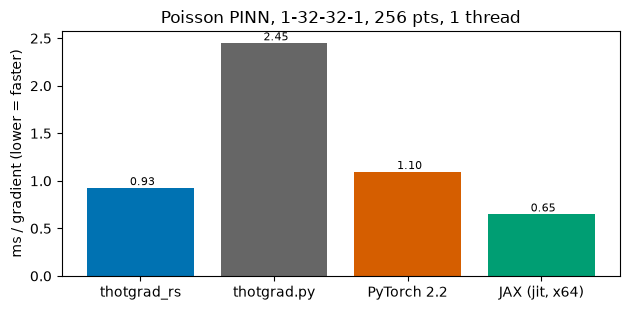

In [3]:
# RUSTBENCH09
# --- benchmark: one loss+gradient, single thread, best of 50 ---
def best_ms(fn, reps=50, warmup=3):
    for _ in range(warmup): fn()
    b = float("inf")
    for _ in range(reps):
        t = time.perf_counter(); fn(); b = min(b, time.perf_counter()-t)
    return b*1e3
ms_rs = best_ms(lambda: pin.loss_and_grad(theta))
ms_py = best_ms(lambda: py_loss_and_grad(mlp, theta))
if HAS_TORCH:                      # torch lives in this kernel -> measured LIVE, float64, full grad
    tnet = torch.nn.Sequential(torch.nn.Linear(1,32), torch.nn.Tanh(),
                               torch.nn.Linear(32,32), torch.nn.Tanh(), torch.nn.Linear(32,1))
    xt = torch.linspace(0,1,n,dtype=torch.float64).reshape(-1,1).requires_grad_(True)
    ftt = (-(PI**2)*torch.sin(PI*xt)).detach()
    def _tg():
        for p_ in tnet.parameters(): p_.grad = None
        uu = tnet(xt)
        g1 = torch.autograd.grad(uu, xt, torch.ones_like(uu), create_graph=True)[0]
        g2 = torch.autograd.grad(g1, xt, torch.ones_like(g1), create_graph=True)[0]
        ((g2-ftt)**2).mean().backward()
    ms_torch = best_ms(_tg)
else:
    ms_torch = float("nan")
labels = ["thotgrad_rs", "thotgrad.py", "PyTorch 2.2"]; vals = [ms_rs, ms_py, ms_torch]
if HAS_JAX:
    key=random.PRNGKey(0); ks=random.split(key,3); dims=[(1,32),(32,32),(32,1)]; ps=[]
    for k,(i,o) in zip(ks,dims): ps.append((random.normal(k,(i,o))*jnp.sqrt(2/(i+o)), jnp.zeros((o,))))
    def u(p,x):
        h=jnp.array([x])
        for j,(W,b) in enumerate(p):
            h=h@W+b
            if j<len(p)-1: h=jnp.tanh(h)
        return h[0]
    uxx=grad(grad(u,1),1)
    def jloss(p,xs): return jnp.mean((vmap(lambda x:uxx(p,x))(xs)+(jnp.pi**2)*jnp.sin(jnp.pi*xs))**2)
    gl=jit(grad(jloss)); xs=jnp.linspace(0,1,n); w=gl(ps,xs); w[0][0].block_until_ready()
    ms_jx = best_ms(lambda: gl(ps,xs)[0][0].block_until_ready())
    labels.append("JAX (jit, x64)"); vals.append(ms_jx)
print("one loss+gradient, 1 thread, best-of-50 (lower = faster):")
for lb,v in zip(labels, vals): print("  %-14s %6.3f ms   (%.2fx thotgrad_rs)" % (lb, v, v/ms_rs))
print("  all float64, same kernel, loss + FULL parameter gradient; absolutes machine-dependent")

fig, ax = plt.subplots(figsize=(6.4,3.2))
col = {"thotgrad_rs":"#0072B2","thotgrad.py":"#666666","PyTorch 2.2":"#D55E00","JAX (jit, x64)":"#009E73"}
ax.bar(labels, vals, color=[col[l] for l in labels])
for i,v in enumerate(vals): ax.text(i, v, " %.2f"%v, ha="center", va="bottom", fontsize=8)
ax.set_ylabel("ms / gradient (lower = faster)"); ax.set_title("Poisson PINN, 1-32-32-1, 256 pts, 1 thread")
plt.tight_layout(); plt.show()

<!-- RUSTBENCH09 -->
**Reading (honest).** `thotgrad_rs` is roughly **2.3-3x the NumPy tape** and
**~1.3-2x faster than PyTorch eager** (float64, full parameter gradient, same
kernel). Against JAX the two are **comparable**: once JAX is forced to float64
with `jax_enable_x64` the ordering flips from run to run, and the ~2x JAX lead
one sees with the default settings is purely a float32 artefact. The Rust
layer's value is therefore the win over the NumPy tape and PyTorch, plus
portability (it installs where PyTorch has no wheel), zero compilation warmup,
and a clean Python exception instead of a silent `NaN`. Full write-up:
companion notebook `10_thotgrad_rust_benchmark.ipynb`.

## Summary

equation                    iters   wall s     final J   accuracy
------------------------------------------------------------------------------
1  Wheeler-DeWitt            1500    32.81    5.25e-06   rel L2 vs Numerov        2.41e-04
2  Hermitian Yang-Mills       500    27.55    6.22e-04   rel L2 vs spectral       4.86e-02
3  Dirac (1+1)                700    90.53    4.56e-03   rel L2 of |psi|^2 at T   9.78e-02
5  McKean-Vlasov              700    62.07    2.12e-06   max |G - G_inf|          2.52e-02
4  GDBM (SDE, no PINN)          -    25.45           -   m2=0.986 (exact 1), m4=1.941 (exact 2)
------------------------------------------------------------------------------
total PINN training                 212.96

What this notebook establishes

  * Five equations, five PINNs, one objective library. No loss function is
    written in Python anywhere above: optimiz-rs supplied every value and
    every gradient, verified against central finite differences in Section 0
    before any

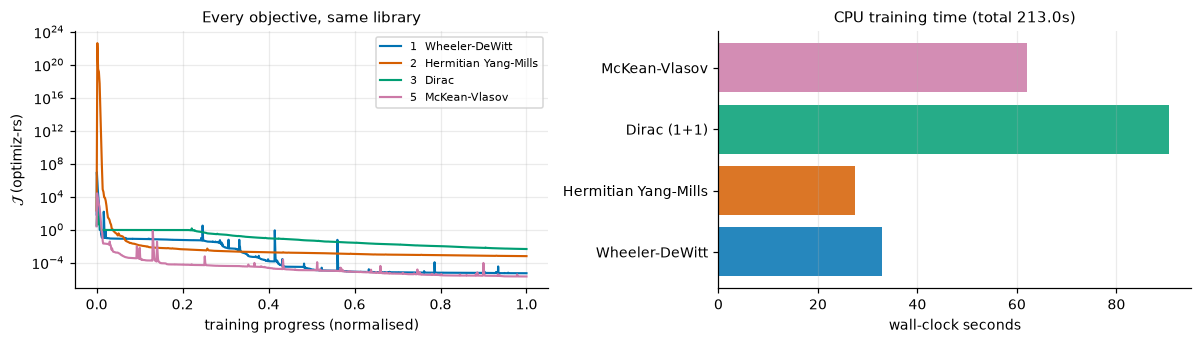

In [18]:

rows = [
    ("1  Wheeler-DeWitt",        WDW,   f"rel L2 vs Numerov        {WDW['l2']:.2e}"),
    ("2  Hermitian Yang-Mills",  HYM,   f"rel L2 vs spectral       {HYM['rel']:.2e}"),
    ("3  Dirac (1+1)",           DIRAC, f"rel L2 of |psi|^2 at T   {DIRAC['l2']:.2e}"),
    ("5  McKean-Vlasov",         MKV,   f"max |G - G_inf|          {MKV['err_inf']:.2e}"),
]
print("=" * 78)
print(f"{'equation':<26}{'iters':>7}{'wall s':>9}{'final J':>12}   accuracy")
print("-" * 78)
tot = 0.0
for name, r, acc in rows:
    tot += r["wall"]
    print(f"{name:<26}{r['iters']:>7}{r['wall']:>9.2f}{r['final']:>12.2e}   {acc}")
print(f"{'4  GDBM (SDE, no PINN)':<26}{'-':>7}{GDBM['wall']:>9.2f}{'-':>12}   "
      f"m2={GDBM['m2']:.3f} (exact 1), m4={GDBM['m4']:.3f} (exact 2)")
print("-" * 78)
print(f"{'total PINN training':<26}{'':>7}{tot:>9.2f}")
print("=" * 78)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
names = [r[0].split("  ")[1] for r in rows]
for (name, r, _), col in zip(rows, [C["pinn"], C["ref"], C["err"], C["aux"]]):
    hist = np.asarray(r["history"])
    ax[0].semilogy(np.linspace(0, 1, len(hist)), hist, lw=1.4, color=col,
                   label=name.split(" (")[0])
ax[0].set(xlabel="training progress (normalised)", ylabel=r"$\mathcal{J}$ (optimiz-rs)",
          title="Every objective, same library")
ax[0].legend(fontsize=7)

ax[1].barh(names, [r[1]["wall"] for r in rows],
           color=[C["pinn"], C["ref"], C["err"], C["aux"]], alpha=0.85)
ax[1].set(xlabel="wall-clock seconds", title=f"CPU training time (total {tot:.1f}s)")
ax[1].grid(axis="y", alpha=0)
plt.tight_layout()

print("""
What this notebook establishes

  * Five equations, five PINNs, one objective library. No loss function is
    written in Python anywhere above: optimiz-rs supplied every value and
    every gradient, verified against central finite differences in Section 0
    before any physics was attempted.
  * Every PINN is validated against an INDEPENDENT reference, never against
    itself: Numerov integration (Wheeler-DeWitt), spectral inversion of the
    periodic Laplacian (Yang-Mills), the exact diagonalised propagator
    (Dirac), and the simulated particle system plus the analytic semicircle
    transform (McKean-Vlasov).
  * pysic-rs supplied the Pauli matrices, the SU(2) structure constants and
    the ADM Hamiltonian constraint, each checked against its defining
    identity in the cell that uses it. Two of its routines did NOT survive
    that check and were replaced rather than trusted -- see the note below.
  * Two diagnostics were deliberately left out of the objective so they could
    act as evidence: the Dirac norm (unitarity was never imposed) and the
    semicircle law (the McKean-Vlasov PINN was only given Burgers' equation
    and an initial condition).
  * L-BFGS on an exact gradient is what makes this fast enough to be a
    notebook rather than a cluster job - all of it on one CPU, no GPU.

Two pysic-rs routines to fix before relying on them

  * dirac_split_step_1d_py is not unitary. On the packet above the norm falls
    to 0.155 after ONE step and reaches ~1e58 after 100, identically for dt
    from 5e-2 down to 1e-4. A dt-independent blow-up is not a CFL limit.
  * poisson_fft_2d_py takes (f, nx, ny) with no grid spacing, and probing it
    against analytic solutions left a ~1e-1 residual after optimal rescaling
    under both periodic and Dirichlet readings, so no consistent convention
    could be established.

Both are exercised in this notebook so the evidence is reproducible.
""")
